# SAR analysis

### USER INPUT

In [ ]:
MINE_POLYGON = "lubienica_mine_polygon.geojson"
VOIVODESHIP = "mazowieckie"
START_DATE = "2024-05-01"
END_DATE = "2024-11-30"
STABLE_POINTS_LONGITUDE = 21.0828
STABLE_POINTS_LATITUDE = 52.7025


### 1. Imports and parameters

In [ ]:
import ee
import re
import json
import geemap
import zipfile
import rasterio
import requests
import numpy as np
import asf_search as asf
from pathlib import Path
from scipy.ndimage import zoom
from pyproj import Transformer
from scipy.ndimage import label
import matplotlib.pyplot as plt
from PIL import Image as PilImage
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde
from matplotlib.patches import Patch
from shapely import wkt as shapely_wkt
from matplotlib.transforms import Bbox
from rasterio.features import rasterize
from datetime import datetime, timedelta
from shapely.geometry import shape, Polygon
from shapely.ops import unary_union, transform
from rasterio.transform import Affine, from_bounds
from esa_snappy import ProductIO, GPF, HashMap, jpy
from asf_search.constants import INTERNAL as ASF_INTERNAL
from IPython.display import display, Image as NotebookImage

Integer = jpy.get_type("java.lang.Integer")
Double = jpy.get_type("java.lang.Double")
Boolean = jpy.get_type("java.lang.Boolean")
GeoPos = jpy.get_type("org.esa.snap.core.datamodel.GeoPos")
PixelPos = jpy.get_type("org.esa.snap.core.datamodel.PixelPos")

if "asf-urs" not in ASF_INTERNAL.AUTH_COOKIES:
    ASF_INTERNAL.AUTH_COOKIES = list(ASF_INTERNAL.AUTH_COOKIES) + ["asf-urs"]

HOME_DIR = Path(r"c:\space_technologies\Kopalnie\open-pit-mining\sar")
EARTHDATA_TOKEN = (HOME_DIR / "token_asf").read_text(encoding="utf-8").strip()
GEE_PROJECT = (HOME_DIR / "gee_project").read_text(encoding="utf-8").strip()

AOI_MINE = None
AOI_STABLE_POINTS = None
AOI_PROCESSING = None

POLYGON_PATH = HOME_DIR / "mines_polygons" / MINE_POLYGON
MINE_NAME = MINE_POLYGON.removesuffix(".geojson").removesuffix("_mine_polygon")

DOWNLOAD_DIR = HOME_DIR / "safe_downloads"
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_DIR = HOME_DIR / ("output_decoherence_maps_" + MINE_NAME)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


### 2. Prepare AOIs


In [ ]:
def make_polygon_buffer(path):
    print("Preparing AOI for analysis ...")
    buffer = 300
    data = json.loads(Path(path).read_text(encoding="utf-8"))
    feats = data["features"] if data.get("type") == "FeatureCollection" else [data]
    geom = unary_union([shape(f["geometry"]) for f in feats])

    lon, lat = geom.centroid.x, geom.centroid.y
    zone = int((lon + 180) // 6) + 1
    utm_epsg = (32600 if lat >= 0 else 32700) + zone

    to_utm = Transformer.from_crs("EPSG:4326", f"EPSG:{utm_epsg}", always_xy=True)
    to_wgs = Transformer.from_crs(f"EPSG:{utm_epsg}", "EPSG:4326", always_xy=True)

    geom_utm = transform(to_utm.transform, geom)
    bbox_utm = geom_utm.buffer(buffer).envelope
    bbox_wgs = transform(to_wgs.transform, bbox_utm)

    print("  polygon bounds:", geom.bounds)
    print("  AOI bounds:", bbox_wgs.bounds)
    print("  buffer: %d m" % buffer)

    return bbox_wgs.wkt


def make_reference_window():
    print("Preparing reference window %s ...")
    buffer = 1500
    zone = int((STABLE_POINTS_LONGITUDE + 180) // 6) + 1
    utm_epsg = (32600 if STABLE_POINTS_LATITUDE >= 0 else 32700) + zone
    
    to_utm = Transformer.from_crs("EPSG:4326", "EPSG:%d" % utm_epsg, always_xy=True)
    to_wgs = Transformer.from_crs("EPSG:%d" % utm_epsg, "EPSG:4326", always_xy=True)

    center = shapely_wkt.loads("POINT (%s %s)" % (STABLE_POINTS_LONGITUDE, STABLE_POINTS_LATITUDE))
    center_utm = transform(to_utm.transform, center)
    bbox_wgs = transform(to_wgs.transform, center_utm.buffer(buffer).envelope)

    print("  window bounds:", bbox_wgs.bounds)
    print("  buffer: %d m" % buffer)
    return bbox_wgs.wkt


### 3. Stack of Sentinel-1 SLC products


In [ ]:
def _search_in_geo_search():
    start = datetime.combine(
        datetime.strptime(START_DATE, "%Y-%m-%d").date(),
        datetime.min.time(),
    )
    end = datetime.combine(
        datetime.strptime(END_DATE, "%Y-%m-%d").date(),
        datetime.max.time(),
    )
    assert end >= start, "END_DATE < START_DATE"

    results = asf.geo_search(
        platform=[asf.PLATFORM.SENTINEL1],
        processingLevel=[asf.PRODUCT_TYPE.SLC],
        beamMode=[asf.BEAMMODE.IW],
        polarization=[asf.POLARIZATION.VV_VH],
        intersectsWith=AOI_MINE,
        start=start,
        end=end,
        maxResults=250,
    )

    whole_aoi_inside = []
    for r in results:
        scene = shape(r.geojson()["geometry"])
        if scene.covers(shapely_wkt.loads(AOI_PROCESSING)):
            whole_aoi_inside.append(r)
    return sorted(whole_aoi_inside, key=lambda r: r.properties.get("startTime", ""))


def _prepare_scene_stack(results):
    assert results, "  No scene in date %s .. %s" % (START_DATE, END_DATE)
    first = results[0]
    rel_orbit = first.properties.get("pathNumber")
    flight_dir = first.properties.get("flightDirection")
    stack = []
    seen_dates = set()

    winter_days = []
    for r in results:
        p = r.properties
        if p.get("pathNumber") != rel_orbit:
            continue
        if p.get("flightDirection") != flight_dir:
            continue
        day = (p.get("startTime") or "")[:10]
        if not day or day in seen_dates:
            continue
        if int(day[5:7]) in (12, 1, 2):
            winter_days.append(day)
            continue
        seen_dates.add(day)
        stack.append(r)
    
    if winter_days:
        print("  rejected %d winter scenes: %s" % (len(winter_days), ", ".join(winter_days)))
    return stack, rel_orbit, flight_dir


def find_sentinel_1_scenes():
    print("Searching for Sentinel-1 scenes ...")

    raw_results = _search_in_geo_search()
    scene_stack, rel_orbit, flight_dir = _prepare_scene_stack(raw_results)

    print("  scenes found: %d" % len(scene_stack))
    print("  date range: %s - %s" % (START_DATE, END_DATE))
    print("  relative orbit = %s;  flight direction = %s" % (rel_orbit, flight_dir))

    for i, r in enumerate(scene_stack, 1):
        p = r.properties
        name = p.get("fileName")
        day = (p.get("startTime"))[:10]
        print("  %2d. %s  %s" % (i, day, name))

    assert len(scene_stack) >= 10, (
        "Need at least 10 scenes for valid analysis — got %d" % len(scene_stack)
    )
    return scene_stack


### 4. Close and remove products

In [31]:
def _java_field(obj, name):
    unsafe = _unsafe()
    cls = obj.getClass()
    while cls is not None:
        try:
            field = cls.getDeclaredField(name)
        except Exception:
            cls = cls.getSuperclass()
            continue
        try:
            field.setAccessible(True)
            return field.get(obj)
        except Exception:
            return unsafe.getObject(obj, unsafe.objectFieldOffset(field))
    return None


def _unsafe():
    Class = jpy.get_type("java.lang.Class")
    unsafe_cls = Class.forName("sun.misc.Unsafe")
    unsafe_field = unsafe_cls.getDeclaredField("theUnsafe")
    unsafe_field.setAccessible(True)
    return unsafe_field.get(None)


def _release_product(product):
    reader = product.getProductReader()
    data_dir = _java_field(reader, "dataDir")
    if data_dir is not None:
        _java_field(_java_field(data_dir, "productDir"), "zipFile").close()
    product.dispose()


def _release_zip_sources(path):
    unsafe = _unsafe()
    Class = jpy.get_type("java.lang.Class")
    source_cls = Class.forName("java.util.zip.ZipFile$Source")
    files_field = source_cls.getDeclaredField("files")
    files = unsafe.getObject(unsafe.staticFieldBase(files_field), unsafe.staticFieldOffset(files_field))
    refs_offset = unsafe.objectFieldOffset(source_cls.getDeclaredField("refs"))
    zfile_offset = unsafe.objectFieldOffset(source_cls.getDeclaredField("zfile"))
    target = str(Path(path).resolve()).lower()
    
    for key in files.keySet().toArray():
        file_obj = unsafe.getObject(key, unsafe.objectFieldOffset(key.getClass().getDeclaredField("file")))
        if str(file_obj.getCanonicalPath()).lower() != target:
            continue
        src = files.remove(key)
        raf = unsafe.getObject(src, zfile_offset)
        raf.close()
        unsafe.putObject(src, zfile_offset, None)
        unsafe.putInt(src, refs_offset, 0)


def close_products(products):
    already_closed = set()
    for product in reversed(products):
        identity = int(product.hashCode())
        if identity in already_closed:
            continue
        already_closed.add(identity)
        _release_product(product)


def remove_scene(path):
    _release_zip_sources(path)
    path.unlink()
    print("Removed: %s" % path.name)


### 5. Download SLC products

In [ ]:
def _zip_is_complete(path, product):
    expected = product.properties.get("bytes")
    if path.stat().st_size != int(expected):
        return False
    if not zipfile.is_zipfile(path):
        return False
    with zipfile.ZipFile(path) as archive:
        return any(name.endswith("manifest.safe") for name in archive.namelist())
        

def scene_day(path):
    return datetime.strptime(re.search(r"(\d{8})T", Path(path).name).group(1), "%Y%m%d")


def start_asf_session():
    session = asf.ASFSession()
    session.auth_cookie_names = list(
        dict.fromkeys(list(session.auth_cookie_names) + ["asf-urs"])
    )
    session.auth_with_token(EARTHDATA_TOKEN)
    print("Logging in ASF Data Search Vertex ...")
    return session


def _initialize_gee():
    ee.Initialize(project=GEE_PROJECT)


def download_images(product, session):
    image = product.properties.get("fileName")
    dest = Path(DOWNLOAD_DIR) / image

    print("Download: %s ..." % image)
    if dest.exists() and _zip_is_complete(dest, product):
        print("  File is already downloaded: %s (%.2f GB)" % (dest.resolve(), dest.stat().st_size / 1e9))
        return dest
    if dest.exists():
        print("  Incomplete file, downloading again: %s (%.2f GB)" % (dest.name, dest.stat().st_size / 1e9))
        _release_zip_sources(dest)
        dest.unlink()

    print("Downloading: %s ..." % image)
    product.download(path=str(Path(DOWNLOAD_DIR)), session=session)

    if not _zip_is_complete(dest, product):
        _release_zip_sources(dest)
        dest.unlink()
        raise RuntimeError("  Downloaded file is incomplete: %s" % dest.name)
        
    print("Downloaded: %s (%.2f GB)" % (dest.name, dest.stat().st_size / 1e9))
    return dest
    

### 6. Open SLC product

In [33]:
def open_slc(zip_path):
    product = ProductIO.readProduct(str(zip_path))
    print("Opening: ", product.getName())
    return product

### 7. Apply Orbit File

In [34]:
def apply_orbit_file(product):
    print("Apply Orbit File ...")
    
    params = HashMap()
    params.put("orbitType", "Sentinel Precise (Auto Download)")
    params.put("polyDegree", Integer(3))
    params.put("continueOnFail", Boolean.FALSE)
    
    orbit = GPF.createProduct("Apply-Orbit-File", params, product)
    return orbit
    

### 8. TOPS Split

In [ ]:
def _swath_to_rectangle(product, band_name):
    band = product.getBand(band_name)
    gc = band.getGeoCoding()
    w, h = band.getRasterWidth(), band.getRasterHeight()
    corners = []

    for x, y in ((0, 0), (w - 1, 0), (w - 1, h - 1), (0, h - 1)):
        gp = GeoPos()
        gc.getGeoPos(PixelPos(float(x), float(y)), gp)
        corners.append((gp.lon, gp.lat))
    return Polygon(corners)


def choose_subswaths_for_aoi(product):
    swaths = []

    for swath in ("IW1", "IW2", "IW3"):
        rectangle = _swath_to_rectangle(product, f"Intensity_{swath}_VV")
        intersection = rectangle.intersection(shapely_wkt.loads(AOI_PROCESSING))
        area = intersection.area if not intersection.is_empty else 0.0
        if area > 0:
            swaths.append(swath)

    print("  subswaths: %s" % ", ".join(swaths))
    return swaths


def topsar_split(product, subswath):
    print("S-1 TOPS Split ...")

    params = HashMap()
    params.put("subswath", subswath)
    params.put("selectedPolarisations", "VV")
    params.put("wktAoi", AOI_PROCESSING)
    
    split = GPF.createProduct("TOPSAR-Split", params, product)
    return split


### 9. Back Geocoding

In [36]:
def back_geocoding(master, slave):
    print("S-1 Back-Geocoding: Copernicus 30m, bilinear ...")

    params = HashMap()
    params.put("demName", "Copernicus 30m Global DEM")
    params.put("demResamplingMethod", "BILINEAR_INTERPOLATION")
    params.put("resamplingType", "BILINEAR_INTERPOLATION")
    params.put("maskOutAreaWithoutElevation", Boolean.TRUE)
    params.put("outputRangeAzimuthOffset", Boolean.FALSE)
    params.put("outputDerampDemodPhase", Boolean.FALSE)
    params.put("disableReramp", Boolean.FALSE)
    Product = jpy.get_type("org.esa.snap.core.datamodel.Product")
    sources = jpy.array(Product, 2)
    sources[0] = master
    sources[1] = slave

    geocoding = GPF.createProduct("Back-Geocoding", params, sources)
    return geocoding
    

### 10. Coherence Estimation

In [ ]:
def coherence_estimation(raster):
    print("Coherence Estimation: Copernicus 30m, topographic phase, window 10x3 ...")

    params = HashMap()
    params.put("subtractFlatEarthPhase", Boolean.TRUE)
    params.put("srpPolynomialDegree", Integer(5))
    params.put("srpNumberPoints", Integer(501))
    params.put("orbitDegree", Integer(3))
    params.put("squarePixel", Boolean.FALSE)
    params.put("cohWinRg", Integer(10))
    params.put("cohWinAz", Integer(3))
    params.put("subtractTopographicPhase", Boolean.TRUE)
    params.put("demName", "Copernicus 30m Global DEM")
    params.put("demResamplingMethod", "BILINEAR_INTERPOLATION")

    coherence = GPF.createProduct("Coherence", params, raster)
    return coherence


### 11. TOPS Deburst

In [ ]:
def topsar_deburst(raster):
    print("S-1 TOPS Deburst ...")

    params = HashMap()
    params.put("selectedPolarisations", "VV")
    
    deburst = GPF.createProduct("TOPSAR-Deburst", params, raster)
    return deburst


### 12. TOPS Merge

In [ ]:
def topsar_merge(raster):
    print("S-1 TOPS Merge ...")

    params = HashMap()
    params.put("selectedPolarisations", "VV")
    Product = jpy.get_type("org.esa.snap.core.datamodel.Product")
    sources = jpy.array(Product, len(raster))
    for i, product in enumerate(raster):
        sources[i] = product

    merged = GPF.createProduct("TOPSAR-Merge", params, sources)
    return merged
    

### 13. Multilook

In [ ]:
def multilook(raster):
    print("Multilook: 6 range x 1 azimuth ...")

    params = HashMap()
    params.put("nRgLooks", Integer(6))
    params.put("nAzLooks", Integer(1))
    params.put("outputIntensity", Boolean.FALSE)
    params.put("grSquarePixel", Boolean.FALSE)

    looked = GPF.createProduct("Multilook", params, raster)
    return looked

### 14. Range-Doppler Terrain Correction

In [ ]:
def terrain_correction(raster):
    print("Range-Doppler Terrain Correction: Copernicus 30m, bilinear ...")

    WGS84 = (
        'GEOGCS["WGS84(DD)",'
        'DATUM["WGS84",SPHEROID["WGS84",6378137.0,298.257223563]],'
        'PRIMEM["Greenwich",0.0],'
        'UNIT["degree",0.017453292519943295],'
        'AXIS["Geodetic longitude",EAST],'
        'AXIS["Geodetic latitude",NORTH],'
        'AUTHORITY["EPSG","4326"]]'
    )

    params = HashMap()
    params.put("demName", "Copernicus 30m Global DEM")
    params.put("demResamplingMethod", "BILINEAR_INTERPOLATION")
    params.put("imgResamplingMethod", "BILINEAR_INTERPOLATION")
    params.put("mapProjection", WGS84)
    params.put("pixelSpacingInMeter", Double(13.92475))
    params.put("nodataValueAtSea", Boolean.TRUE)
    params.put("saveSelectedSourceBand", Boolean.TRUE)
    params.put("saveDEM", Boolean.FALSE)
    params.put("saveLatLon", Boolean.FALSE)
    params.put("saveLocalIncidenceAngle", Boolean.FALSE)
    params.put("saveLayoverShadowMask", Boolean.TRUE)
    params.put("outputComplex", Boolean.FALSE)
    params.put("alignToStandardGrid", Boolean.TRUE)
    params.put("applyRadiometricNormalization", Boolean.FALSE)

    terrain_correction = GPF.createProduct("Terrain-Correction", params, raster)
    return terrain_correction
    

### 15. Subset

In [ ]:
def subset(raster, region):
    print("Subset ...")

    params = HashMap()
    params.put("geoRegion", region)
    params.put("copyMetadata", Boolean.TRUE)
    params.put("fullSwath", Boolean.FALSE)
    
    subset = GPF.createProduct("Subset", params, raster)
    return subset

### 16. Rasters to arrays


In [ ]:
def _band_name(raster, key):
    for name in raster.getBandNames():
        if key(str(name).lower()):
            return str(name)
    return None


def _read_pixels(band):
    width = band.getRasterWidth()
    height = band.getRasterHeight()
    arr = np.empty(width * height, dtype=np.float32)
    band.readPixels(0, 0, width, height, arr)
    return arr.reshape(height, width)


def _scene_grid(raster):
    gc = raster.getSceneGeoCoding()
    width = raster.getSceneRasterWidth()
    height = raster.getSceneRasterHeight()

    def geo(x, y):
        gp = GeoPos()
        gc.getGeoPos(PixelPos(float(x), float(y)), gp)
        return float(gp.lon), float(gp.lat)

    lon00, lat00 = geo(0, 0)
    lon10, _ = geo(1, 0)
    _, lat01 = geo(0, 1)
    dx = lon10 - lon00
    dy = lat01 - lat00
    grid = Affine(dx, 0.0, lon00 - dx / 2.0, 0.0, dy, lat00 - dy / 2.0)
    left = grid.c
    top = grid.f
    extent = (left, left + dx * width, top + dy * height, top)
    profile = {
        "driver": "GTiff",
        "dtype": "float32",
        "count": 1,
        "width": width,
        "height": height,
        "crs": "EPSG:4326",
        "transform": grid,
    }
    return grid, extent, profile


def raster_to_array(raster, master_zip, slave_zip, label):
    print("Convert raster %s to array ..." % label)
    master_day = scene_day(master_zip)
    slave_day = scene_day(slave_zip)
    master_slave_dates = "%s_%s" % (master_day.strftime("%Y.%m.%d"), slave_day.strftime("%Y.%m.%d"))

    coherence_name = _band_name(raster, lambda name: name.startswith("coh"))
    coh_pixels = _read_pixels(raster.getBand(coherence_name))
    coherence = np.where((coh_pixels < 0) | (coh_pixels > 1), np.nan, coh_pixels).astype(np.float32, copy=False)

    shadow_name = _band_name(raster, lambda name: "layover" in name or "shadow" in name)
    shadow = _read_pixels(raster.getBand(shadow_name)) if shadow_name is not None else None

    grid, extent, profile = _scene_grid(raster)
    return {
        "name": master_slave_dates,
        "coherence": coherence,
        "shadow": shadow,
        "transform": grid,
        "extent": extent,
        "profile": profile,
    }


### 17. Stable points

Stable points ...
  reference window: pultusk
  coherence rasters: 17
  buildings asset: projects/mining-457808/assets/mazowieckie/buildings
  building pixels in the reference window: 5139
  building pixels in the reference: 5138
  building pixels with mean > 0.8 and std < 0.2: 625
  after removing isolated pixels: 454
  stable pixels: 454
  stable coherence mean: 0.855
  stable coherence std: 0.057
Saved stable points: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_reference\pultusk\stable_points.tif
Saved stable-point report: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_coherence\stable_points.json
Saved stable-point map: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_reference\pultusk\stable_points.png


C:\Users\User\AppData\Local\Temp\ipykernel_20080\551311678.py:150: RuntimeWarning: Mean of empty slice
  mean = np.nanmean(np.where(reference, stack, np.nan), axis=0)
c:\space_technologies\Kopalnie\open-pit-mining\.venv\lib\site-packages\numpy\lib\_nanfunctions_impl.py:2035: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


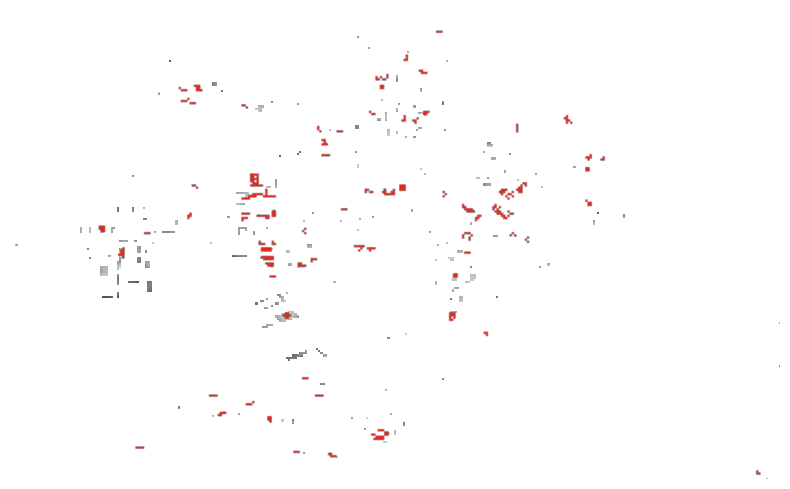

In [ ]:
def _polygons_from_gee(collection):
    data = collection.getInfo() or {}
    polygons = []
    for feature in data.get("features", []):
        geometry = feature.get("geometry")
        geom = shape(geometry)
        if not geom.is_valid:
            geom = geom.buffer(0)
        if geom.geom_type == "Polygon":
            polygons.append(geom)
        elif geom.geom_type == "MultiPolygon":
            polygons.extend([part for part in geom.geoms if not part.is_empty])
    return polygons


def _raster_mask(polygons, shape_hw, grid_transform):
    mask =  rasterize(
        [(geom, 1) for geom in polygons],
        out_shape=shape_hw,
        transform=grid_transform,
        fill=0,
        dtype="uint8",
    )
    return mask


def _compact_mask(mask, min_pixels):
    labeled, n = label(mask, structure=np.ones((3, 3), dtype=int))
    if n == 0:
        return np.zeros(mask.shape, dtype=bool)
    counts = np.bincount(labeled.ravel())
    keep = counts >= min_pixels
    keep[0] = False
    return keep[labeled]


def _show_stable_points(mean, stable):
    fig, ax = plt.subplots(figsize=(8, 8))
    show = np.ma.masked_invalid(mean)
    ax.imshow(show, cmap="gray", vmin=0, vmax=1)
    overlay = np.zeros(mean.shape + (4,), dtype=np.float32)
    overlay[stable] = (0.88, 0.04, 0.0, 0.85)
    ax.imshow(overlay)
    ax.set_axis_off()
    fig.tight_layout()
    plt.show()


def calculate_stable_points(references):
    print("Stable points ...")

    base = references[0]

    _initialize_gee()
    aoi = ee.Geometry(shapely_wkt.loads(AOI_STABLE_POINTS).__geo_interface__)

    stack = np.stack([ref["coherence"] for ref in references], axis=0)
    grid_transform = base["transform"]
    shape_hw = stack.shape[1:]

    folder = "projects/mining-457808/assets/%s" % VOIVODESHIP
    buildings = _polygons_from_gee(ee.FeatureCollection("%s/buildings" % folder).filterBounds(aoi))
    if not buildings:
        raise RuntimeError("No building in the reference window")
    building_mask = _raster_mask(buildings, shape_hw, grid_transform).astype(bool)

    count = np.sum(np.isfinite(stack), axis=0)
    enough = count >= max(3, int(0.8 * stack.shape[0]))
    reference = building_mask & enough
    print("  building pixels in the reference window: %d" % int(reference.sum()))

    mean = np.nanmean(np.where(reference, stack, np.nan), axis=0)
    std = np.nanstd(np.where(reference, stack, np.nan), axis=0)
    finite = reference & np.isfinite(mean) & np.isfinite(std)
    strict = finite & (mean > 0.8) & (std < 0.2)
    stable = _compact_mask(strict, 3)
    
    print("  building pixels with mean > 0.8 and std < 0.2: %d" % int(strict.sum()))
    print("  after removing isolated pixels, stable pixels accepted: %d" % int(stable.sum()))
    accepted = int(stable.sum()) >= 30
    if not accepted:
        raise RuntimeError("Fewer than 30 compact building pixels. The analysis cannot continue.")

    pairs = []
    gammas = []
    center = float("nan")

    print("  stable coherence mean: %.3f" % float(np.nanmean(mean[stable])))
    print("  stable coherence std: %.3f" % float(np.nanmean(std[stable])))

    for ref, image in zip(references, stack):
        values = image[stable]
        values = values[np.isfinite(values)]
        gamma = float(np.mean(values)) if values.size else float("nan")
        gammas.append(gamma)
        pairs.append({
            "name": ref["name"],
            "gamma_stable": None if np.isnan(gamma) else round(gamma, 4),
        })
    
    center = float(np.nanmedian(gammas))
    kept = []
    for pair, gamma in zip(pairs, gammas):
        if not np.isnan(gamma) and gamma >= center - 0.10:
            kept.append(pair)
        else:
            print("  reject pair %s, gamma_stable %.3f" % (pair["name"], gamma))

    print("  pairs kept: %d" % len(kept))
    if not kept:
        raise RuntimeError("Every pair was rejected. The analysis cannot continue.")

    _show_stable_points(mean, stable)
    return kept


### 18. Water and vegetation mask from Sentinel-2

In [ ]:
def _resize_to(arr, shape_hw):
    arr = np.asarray(arr, dtype=np.float32)
    if arr.ndim == 3:
        arr = arr[:, :, 0]
    zy, zx = shape_hw[0] / arr.shape[0], shape_hw[1] / arr.shape[1]
    out = zoom(arr, (zy, zx), order=1)
    fixed = np.full(shape_hw, np.nan, dtype=np.float32)
    h, w = min(shape_hw[0], out.shape[0]), min(shape_hw[1], out.shape[1])
    fixed[:h, :w] = out[:h, :w]
    return fixed


def _extend_date_range_by_month(day, months):
    month = day.month - 1 + months
    year = day.year + month // 12
    month = month % 12 + 1
    lengths = [31, 29 if year % 4 == 0 and (year % 100 != 0 or year % 400 == 0) else 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]
    return day.replace(year=year, month=month, day=min(day.day, lengths[month - 1]))


def _image_label(image):
    meta = ee.Dictionary({
        "id": image.get("system:index"),
        "date": ee.Date(image.get("system:time_start")).format("YYYY-MM-dd"),
    }).getInfo()
    return "%s %s" % (meta["date"], meta["id"])


def _contains_whole_aoi(image, aoi):
    contains_aoi = bool(image.geometry().contains(aoi, ee.ErrorMargin(1)).getInfo())
    return contains_aoi


def _check_clouds(image, aoi):
    scl = image.select("SCL")
    cloud = (scl.eq(3).Or(scl.eq(8)).Or(scl.eq(9)).Or(scl.eq(10)).rename("cloud"))
    clouds_fraction = cloud.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=aoi,
        scale=20,
        maxPixels=1e8,
    ).get("cloud").getInfo()
    return clouds_fraction


def ndwi_mask(image, extent, shape_hw):
    ndwi = image.select(["B3", "B8"]).divide(10000).normalizedDifference(["B3", "B8"]).rename("NDWI")
    minx, maxx, miny, maxy = extent
    region = ee.Geometry.Rectangle([minx, miny, maxx, maxy], proj="EPSG:4326", geodesic=False)
    arr = geemap.ee_to_numpy(ndwi, region=region, scale=20, bands=["NDWI"])
    ndwi_arr = _resize_to(arr, shape_hw)

    water = np.isfinite(ndwi_arr) & (ndwi_arr >= -0.1)
    if not water.any():
        print("  No water on the image")
    return water

def ndvi_mask(image, extent, shape_hw):
    ndvi = image.select(["B8", "B4"]).divide(10000).normalizedDifference(["B8", "B4"]).rename("NDVI")
    minx, maxx, miny, maxy = extent
    region = ee.Geometry.Rectangle([minx, miny, maxx, maxy], proj="EPSG:4326", geodesic=False)
    arr = geemap.ee_to_numpy(ndvi, region=region, scale=20, bands=["NDVI"])
    ndvi_arr = _resize_to(arr, shape_hw)

    vegetation = np.isfinite(ndvi_arr) & (ndvi_arr >= 0.35)
    if not vegetation.any():
        print("  No vegetation in the mine area")
    return vegetation


def find_sentinel_2_images(start, end):
    print("Searching for Sentinel-2 images ...")
    print("  date range: %s - %s" % (start.strftime("%Y-%m-%d"), end.strftime("%Y-%m-%d")))

    aoi = ee.Geometry(shapely_wkt.loads(AOI_MINE).__geo_interface__)

    start = datetime.combine(start.date(), datetime.min.time())
    end = datetime.combine(end.date(), datetime.max.time())

    col = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(aoi)
        .filterDate(start, end)
        .sort("system:time_start")
    )

    total = col.size().getInfo()
    if not total:
        return []
    print("  images found: %d" % total)

    listed = col.toList(total)
    images_stack = []
    for image in range(total):
        image = ee.Image(listed.get(image))
        label = _image_label(image)

        if not _contains_whole_aoi(image, aoi):
            print("  reject: %s, AOI is not fully inside the scene" % label)
            continue

        clouds = _check_clouds(image, aoi)
        if clouds is None or clouds > 0:
            print("  reject: %s, clouds cover AOI" % label)
            continue

        print("  accept: %s" % label)
        images_stack.append(image)

    print("  images accepted: %d" % len(images_stack))
    return images_stack


### 19. Normalized Differential Activity Index

In [ ]:
def _shadow_mask(record, shape_hw, announced):
    shadow = record["shadow"]
    if shadow is None:
        if not announced[0]:
            print("  Shadow mask is missing. Radar shadow is not removed.")
            announced[0] = True
        return np.zeros(shape_hw, dtype=bool)
    return np.isfinite(shadow) & (shadow > 0)


def _ndai_threshold(values):
    values = np.asarray(values, dtype=np.float64)
    values = values[np.isfinite(values)]
    low, high = np.quantile(values, [0.005, 0.995])
    clipped = np.clip(values, low, high)
    if np.std(clipped) < 1e-6:
        return float(np.median(clipped)), "median, no spread"
    if clipped.size > 200000:
        clipped = np.random.default_rng(0).choice(clipped, 200000, replace=False)

    density_grid = np.linspace(float(low), float(high), 512)
    density = gaussian_kde(clipped)(density_grid)
    slope = np.sign(np.diff(density))
    valleys = np.where((slope[:-1] < 0) & (slope[1:] > 0))[0] + 1
    span = float(high - low)
    interior = [
        index for index in valleys
        if low + 0.1 * span < density_grid[index] < high - 0.1 * span
    ]
    if len(interior):
        best = min(interior, key=lambda index: density[index])
        return float(density_grid[best]), "density minimum"

    hist, edges = np.histogram(clipped, bins=256)
    centers = (edges[:-1] + edges[1:]) / 2.0
    weight_low = np.cumsum(hist).astype(np.float64)
    weight_high = np.cumsum(hist[::-1])[::-1].astype(np.float64)
    sum_low = np.cumsum(hist * centers)
    sum_high = np.cumsum((hist * centers)[::-1])[::-1]
    mean_low = sum_low / np.maximum(weight_low, 1)
    mean_high = sum_high / np.maximum(weight_high, 1)
    between = weight_low[:-1] * weight_high[1:] * (mean_low[:-1] - mean_high[1:]) ** 2
    return float(centers[int(np.argmax(between))]), "otsu, no interior minimum"


def _write_float(path, arr, profile):
    stored = np.where(np.isfinite(arr), arr, -9999).astype(np.float32)
    out_profile = profile.copy()
    out_profile.update(driver="GTiff", dtype="float32", count=1, nodata=-9999, compress="deflate")
    path.unlink()
    with rasterio.open(path, "w", **out_profile) as dst:
        dst.write(stored, 1)


def activity_map(arr, polygon, master_day, slave_day, extent):
    ...

def activity_map_with_sentinel2_references(array, polygon, master_day, slave_day, extent):
    ...

def ndai_maps(stack_coherence_mine, gamma_stable_for_raster):
    print("Calculating Normalized Differential Activity Index maps ...")

    by_name = {raster["name"]: raster for raster in stack_coherence_mine}
    mine_raster = by_name[gamma_stable_for_raster[0]["name"]]
    extent = mine_raster["extent"]
    profile = mine_raster["profile"]
    grid_transform = mine_raster["transform"]
    shape_hw = mine_raster["coherence"].shape

    mine = shape(json.loads(POLYGON_PATH.read_text(encoding="utf-8"))["features"][0]["geometry"])
    mine_mask = _raster_mask([mine], shape_hw, grid_transform).astype(bool)
    announced = [False]
    samples = []
    prepared = []
    for reference in gamma_stable_for_raster:
        master_day = datetime.strptime(reference["name"].split("_")[0], "%Y.%m.%d")
        slave_day = datetime.strptime(reference["name"].split("_")[1], "%Y.%m.%d")
        image = find_sentinel_2_images(slave_day + timedelta(days=1), _extend_date_range_by_month(slave_day, 1))[0]

        if not image:
            print("  skip %s, no cloud-free Sentinel-2 scene within one month after" % reference["name"])
            continue
        print("  Sentinel-2 scene for %s: %s" % (reference["name"], _image_label(image)["date"]))
        
        water = ndwi_mask(image, extent, shape_hw)
        vegetation = ndvi_mask(image, extent, shape_hw) & mine_mask

        mine_raster = by_name[reference["name"]]
        gamma = mine_raster["coherence"]
        shadow = _shadow_mask(mine_raster, shape_hw, announced)
        numerator = reference["gamma_stable"] - gamma
        denominator = reference["gamma_stable"] + gamma
        ndai = np.full(shape_hw, np.nan, dtype=np.float32)
        valid = np.isfinite(gamma) & (np.abs(denominator) > 1e-6)
        ndai[valid] = numerator[valid] / denominator[valid]
        sample = ndai[mine_mask & ~water & ~vegetation & ~shadow & np.isfinite(ndai)]
        if sample.size:
            samples.append(sample)
        prepared.append((reference, ndai, shadow, water, vegetation, master_day, slave_day))

    if not samples:
        raise RuntimeError("No NDAI samples inside the mine")

    pooled = np.concatenate(samples)
    threshold, rule = _ndai_threshold(pooled)
    print("  NDAI threshold: %.4f, rule used: %s)" % (threshold, rule))

    saved = []
    for reference, ndai, shadow, water, vegetation, master_day, slave_day in prepared:
        change = np.isfinite(ndai) & (ndai > threshold) & ~water & ~vegetation & ~shadow
        print("  %s change pixels: %d" % (reference["name"], int(change.sum())))

        ndai_path = OUTPUT_DIR / ("%s_ndai.tif" % reference["name"])
        _write_float(ndai_path, ndai, profile)
        map = activity_map(change.astype(np.uint8), mine, master_day, slave_day, extent)
        saved.append(map)
        activity_map_with_sentinel2_references(change.astype(np.uint8), mine, master_day, slave_day, extent)

    return saved

### 20. Visualization

In [ ]:
def _draw_outline(ax, arr, geom, extent):
    if isinstance(geom, str):
        geom = shapely_wkt.loads(geom)
    if geom.geom_type == "Polygon":
        parts = [geom]
    else:
        parts = [part for part in geom.geoms if part.geom_type == "Polygon"]

    minx, maxx, miny, maxy = extent
    arr = np.asarray(arr)
    height, width = arr.shape[:2]

    for part in parts:
        rings = [part.exterior, *part.interiors]
        for ring in rings:
            xs, ys = ring.xy
            cols = (np.asarray(xs) - minx) / (maxx - minx) * width - 0.5
            rows = (maxy - np.asarray(ys)) / (maxy - miny) * height - 0.5
            ax.plot(cols, rows, color="#e10600", linewidth=1.4)

def _first_sentinel_2_image(anchor, direction):
    if direction < 0:
        start = _extend_date_range_by_month(anchor, -1)
        end = anchor - timedelta(days=1)
    else:
        start = anchor + timedelta(days=1)
        end = _extend_date_range_by_month(anchor, 1)

    images = find_sentinel_2_images(start, end)
    if not images:
        return None
    image = images[-1] if direction < 0 else images[0]
    date = datetime.strptime(_image_label(image).split()[0], "%Y-%m-%d")
    return image, date


def _sentinel_rgb(image, extent, shape_hw):
    rgb = image.select(["B4", "B3", "B2"])
    minx, maxx, miny, maxy = extent
    region = ee.Geometry.Rectangle([minx, miny, maxx, maxy], proj="EPSG:4326", geodesic=False)
    arr = geemap.ee_to_numpy(rgb, region=region, scale=10, bands=["B4", "B3", "B2"])
    arr = np.asarray(arr, dtype=np.float32)
    if arr.ndim == 3 and arr.shape[0] == 3 and arr.shape[-1] != 3:
        arr = np.moveaxis(arr, 0, -1)
    arr = np.clip(arr[:, :, :3] / 3000.0, 0, 1)

    zy = shape_hw[0] / arr.shape[0]
    zx = shape_hw[1] / arr.shape[1]
    out = zoom(arr, (zy, zx, 1), order=1)
    fixed = np.zeros((shape_hw[0], shape_hw[1], 3), dtype=np.float32)
    h = min(shape_hw[0], out.shape[0])
    w = min(shape_hw[1], out.shape[1])
    fixed[:h, :w] = out[:h, :w]
    return np.clip(fixed, 0, 1)

def _draw_activity_map(ax, legend_ax, array, polygon, extent):
    ax.imshow(array, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    _draw_outline(ax, array, polygon, extent)
    ax.set_axis_off()
    legend_ax.set_axis_off()
    legend = legend_ax.legend(
        handles=[
            Patch(facecolor="white", edgecolor="black", label="surface change"),
            Patch(facecolor="black", edgecolor="black", label="no change"),
            Line2D([0], [0], color="#e10600", linewidth=2, label="mine area"),
        ],
        title="Legend",
        loc="upper center",
        bbox_to_anchor=(0.5, 1),
        borderaxespad=0,
        borderpad=0.8,
        ncol=3,
        columnspacing=2.5,
        frameon=True,
        fancybox=False,
        edgecolor="#CCCCCC",
        facecolor="white",
        framealpha=1,
        fontsize=10.5,
        title_fontsize=12,
    )
    legend._legend_box.sep = 1.0 * 10.5


def activity_map(array, polygon, master_day, slave_day, extent):
    dates = "%s - %s" % (master_day.strftime("%d.%m.%Y"), slave_day.strftime("%d.%m.%Y"))
    arr_h, arr_w = np.asarray(array).shape[:2]
    map_w, gap, title_h, legend_h = 7.0, 0.24, 0.52, 0.67
    margin_v = 0.27
    margin_h = 0.27
    map_h = map_w * arr_h / arr_w
    fig_w = 2 * margin_h + map_w
    fig_h = 2 * margin_v + title_h + gap + map_h + gap + legend_h
    fig = plt.figure(figsize=(fig_w, fig_h), dpi=150)
    legend_ax = fig.add_axes([margin_h / fig_w, margin_v / fig_h, map_w / fig_w, legend_h / fig_h])
    ax = fig.add_axes(
        [margin_h / fig_w, (margin_v + legend_h + gap) / fig_h, map_w / fig_w, map_h / fig_h]
    )

    fig.text(
        0.5, 1 - margin_v / fig_h, "Activity Map",
        fontsize=16, fontweight="bold", ha="center", va="top",
    )
    fig.text(
        0.5, 1 - (margin_v + 0.34) / fig_h, "%s  |  %s" % (MINE_NAME, dates),
        fontsize=12, color="black", ha="center", va="top",
    )
    _draw_activity_map(ax, legend_ax, array, polygon, extent)

    out = OUTPUT_DIR / ("%s-%s_activity_map.png" % (master_day.strftime("%Y.%m.%d"), slave_day.strftime("%Y.%m.%d")))
    fig.savefig(out, facecolor="white")
    print("Saved map: %s" % out)
    plt.show()
    return out


def activity_map_with_sentinel2_references(array, polygon, master_day, slave_day, extent):
    dates = "%s - %s" % (master_day.strftime("%d.%m.%Y"), slave_day.strftime("%d.%m.%Y"))
    shape_hw = np.asarray(array).shape[:2]

    panels = []
    for hit in (_first_sentinel_2_image(master_day, -1), _first_sentinel_2_image(slave_day, 1)):
        if hit is None:
            panels.append(None)
            continue
        image, date = hit
        rgb = _sentinel_rgb(image, extent, shape_hw)
        panels.append((rgb, date))

    arr_h, arr_w = shape_hw
    s2_w, col_gap, row_gap = 3.35, 0.36, 0.28
    title_h, caption_h, legend_h = 0.52, 0.36, 0.67
    margin_v, margin_h = 0.27, 0.27
    s2_h = s2_w * arr_h / arr_w
    sar_w = 2 * s2_w + col_gap
    sar_h = sar_w * arr_h / arr_w
    fig_w = 2 * margin_h + sar_w
    fig_h = (
        2 * margin_v + title_h + caption_h + s2_h + row_gap
        + caption_h + sar_h + row_gap + legend_h
    )
    fig = plt.figure(figsize=(fig_w, fig_h), dpi=150)

    y_legend = margin_v
    y_sar = y_legend + legend_h + row_gap
    y_s2 = y_sar + sar_h + caption_h + row_gap
    legend_ax = fig.add_axes([margin_h / fig_w, y_legend / fig_h, sar_w / fig_w, legend_h / fig_h])
    sar_ax = fig.add_axes([margin_h / fig_w, y_sar / fig_h, sar_w / fig_w, sar_h / fig_h])
    left_ax = fig.add_axes([margin_h / fig_w, y_s2 / fig_h, s2_w / fig_w, s2_h / fig_h])
    right_ax = fig.add_axes(
        [(margin_h + s2_w + col_gap) / fig_w, y_s2 / fig_h, s2_w / fig_w, s2_h / fig_h]
    )

    fig.text(
        0.5, 1 - margin_v / fig_h, "Activity Map and Optical Images Comparison",
        fontsize=16, fontweight="bold", ha="center", va="top",
    )
    fig.text(
        0.5, 1 - (margin_v + 0.34) / fig_h, MINE_NAME,
        fontsize=12, color="black", ha="center", va="top",
    )

    for ax, panel in ((left_ax, panels[0]), (right_ax, panels[1])):
        if panel is None:
            ax.imshow(np.full((shape_hw[0], shape_hw[1], 3), 0.94, dtype=np.float32), interpolation="nearest")
            ax.text(
                shape_hw[1] / 2, shape_hw[0] / 2,
                "No image found\nwithin one month",
                ha="center", va="center", fontsize=11, color="#333333",
            )
            caption = "Optical Image"
        else:
            rgb, date = panel
            ax.imshow(rgb, interpolation="nearest")
            _draw_outline(ax, array, polygon, extent)
            caption = "Optical Image  |  %s" % date.strftime("%d.%m.%Y")
            
        ax.set_axis_off()
        pos = ax.get_position()
        fig.text(
            pos.x0 + pos.width / 2, pos.y1 + 0.012, caption,
            fontsize=13, ha="center", va="bottom",
        )

    _draw_activity_map(sar_ax, legend_ax, array, polygon, extent)
    sar_pos = sar_ax.get_position()
    fig.text(
        sar_pos.x0 + sar_pos.width / 2, sar_pos.y1 + 0.012, "Activity Map  |  %s" % dates,
        fontsize=13, ha="center", va="bottom",
    )

    out = OUTPUT_DIR / ("%s-%s_activity_map_optical_images.png" % (master_day.strftime("%Y.%m.%d"), slave_day.strftime("%Y.%m.%d")))
    fig.savefig(out, facecolor="white")
    print("Saved map: %s" % out)
    plt.show()
    return out


def show_activity_gif(paths):
    frames = [PilImage.open(path).convert("RGB") for path in paths]
    gif_path = OUTPUT_DIR / "activity_maps.gif"
    frames[0].save(gif_path, save_all=True, append_images=frames[1:], duration=1000, loop=0)
    print("Saved GIF: %s" % gif_path)
    display(NotebookImage(filename=str(gif_path)))



### 21. Run workflow

In [ ]:
def coherence_analysis(master_zip, slave_zip):
    master_slc = open_slc(master_zip)
    slave_slc = open_slc(slave_zip)

    master_orb = apply_orbit_file(master_slc)
    slave_orb = apply_orbit_file(slave_slc)

    subswath = choose_subswaths_for_aoi(master_orb)

    master_orb_split = { swath: topsar_split(master_orb, swath) for swath in subswath }
    slave_orb_split = { swath: topsar_split(slave_orb, swath) for swath in subswath }

    orb_split_stack = { swath: back_geocoding(master_orb_split[swath], slave_orb_split[swath]) for swath in subswath }
    orb_split_stack_coh = { swath: coherence_estimation(orb_split_stack[swath]) for swath in subswath }
    orb_split_stack_coh_deb = { swath: topsar_deburst(orb_split_stack_coh[swath]) for swath in subswath }

    if len(orb_split_stack_coh_deb) > 1:
        orb_split_stack_coh_deb_merge = topsar_merge([orb_split_stack_coh_deb[swath] for swath in subswath])
    else:
        orb_split_stack_coh_deb_merge = orb_split_stack_coh_deb[subswath[0]]

    orb_split_stack_coh_deb_merge_multi = multilook(orb_split_stack_coh_deb_merge)
    orb_split_stack_coh_deb_merge_multi_tc = terrain_correction(orb_split_stack_coh_deb_merge_multi)

    mine_sub = subset(orb_split_stack_coh_deb_merge_multi_tc, AOI_MINE)
    stable_points_sub = subset(orb_split_stack_coh_deb_merge_multi_tc, AOI_STABLE_POINTS)

    opened = [
        master_slc, slave_slc, master_orb, slave_orb,
        *master_orb_split.values(), *slave_orb_split.values(),
        *orb_split_stack.values(),
        *orb_split_stack_coh.values(),
        *orb_split_stack_coh_deb.values(),
        orb_split_stack_coh_deb_merge,
        orb_split_stack_coh_deb_merge_multi, 
        orb_split_stack_coh_deb_merge_multi_tc, 
        mine_sub, stable_points_sub,
    ]

    mine = raster_to_array(mine_sub, master_zip, slave_zip, "mine")
    stable_points = raster_to_array(stable_points_sub, master_zip, slave_zip, "stable_points")

    close_products(opened)

    return {"mine": mine, "stable_points": stable_points}


AOI_MINE = make_polygon_buffer(POLYGON_PATH)
AOI_STABLE_POINTS = make_reference_window()
AOI_PROCESSING = unary_union([
    shapely_wkt.loads(AOI_MINE),
    shapely_wkt.loads(AOI_STABLE_POINTS),
]).wkt

stack_sentinel1_scenes = find_sentinel_1_scenes()

session = start_asf_session()
master_day = download_images(stack_sentinel1_scenes[0], session)
slave = download_images(stack_sentinel1_scenes[1], session)

stack_coherence_mine = []
stack_coherence_reference = []

for scene in range(len(stack_sentinel1_scenes) - 1):
    print("Pair %d/%d  %s  x  %s" % (scene + 1, len(stack_sentinel1_scenes) - 1, master_day.name, slave.name))

    gap_days = (scene_day(slave) - scene_day(master_day)).days
    if gap_days <= 13:
        coherence = coherence_analysis(master_day, slave)
        stack_coherence_mine.append(coherence["mine"])
        stack_coherence_reference.append(coherence["stable_points"])
    else:
        print("  skip pair, %d days between scenes, pair is valid when gap is 13 days or less" % gap_days)

    #remove_scene(master)

    if scene + 2 < len(stack_sentinel1_scenes):
        master_day = slave
        slave = download_images(stack_sentinel1_scenes[scene + 2], session)

gamma_stable_for_raster = calculate_stable_points(stack_coherence_reference)
saved_ndai_maps = ndai_maps(stack_coherence_mine, gamma_stable_for_raster)

show_activity_gif(saved_ndai_maps)


NameError: name 'make_polygon_buffer' is not defined